In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from boxbox.loading import load_json

In [15]:
from boxbox.loading import load_json

race_data = load_json(
    "../data/british_gp/session_laptimes.json"
)

type(race_data)



dict

In [157]:
import pandas as pd

df = pd.DataFrame(race_data)


In [158]:
import importlib
import boxbox.cleaning

importlib.reload(boxbox.cleaning)

<module 'boxbox.cleaning' from 'c:\\Users\\enric\\Desktop\\Box_Box\\boxbox\\cleaning.py'>

In [147]:
from boxbox.cleaning import prepare_lap_data
from boxbox.cleaning import remove_pit_laps
from boxbox.cleaning import remove_neutralised_laps
from boxbox.cleaning import add_pace_loss

laps = prepare_lap_data(df)
laps = remove_pit_laps(laps)
laps = remove_neutralised_laps(laps)
laps = add_pace_loss(laps)


In [130]:
laps["status"] = pd.to_numeric(
    laps["status"],
    errors="coerce"
)


Tyre Age vs Pace Loss - Charles Leclerc

In [176]:
# Analysis dataset
degradation_data = laps[
    laps["life"] > 1
].copy()

# Select Leclerc from the filtered dataset
lec = degradation_data[
    degradation_data["drv"] == "LEC"
]

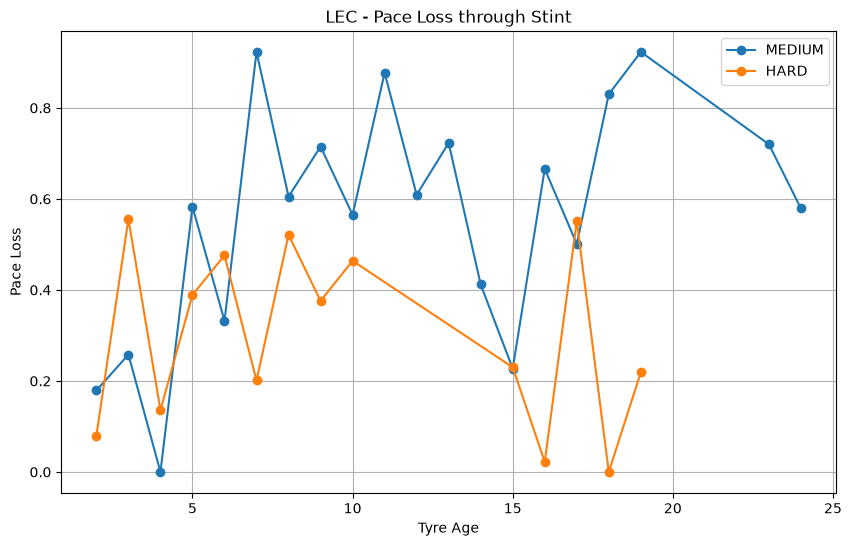

In [179]:
plt.figure(figsize=(10,6))

for compound in lec["compound"].unique():

    subset = lec[
        lec["compound"] == compound
    ].sort_values("life")

    plt.plot(
        subset["life"],
        subset["pace_loss"],
        marker="o",
        label=compound
    )

plt.xlabel("Tyre Age")
plt.ylabel("Pace Loss")
plt.title("LEC - Pace Loss through Stint")

plt.legend()
plt.grid(True)
plt.show()

In [185]:
from scipy.stats import linregress

In [186]:
medium_fit = linregress(
    medium["life"],
    medium["pace_loss"]
)

hard_fit = linregress(
    hard["life"],
    hard["pace_loss"]
)

print("Medium slope:", medium_fit.slope)
print("Medium R²:", medium_fit.rvalue**2)

print("Hard slope:", hard_fit.slope)
print("Hard R²:", hard_fit.rvalue**2)

Medium slope: 0.01847364419665481
Medium R²: 0.21242836991799427
Hard slope: -0.008294319066147984
Hard R²: 0.06157360063049842
